# Pump Sound Fault Detection: end-to-end ML pipeline

**Can we tell from a 10-second recording whether a water pump is about to fail?**

My Intro to ML summative predicted the functional status of rural water points in Tanzania from *tabular* records
(installer, age, extraction type...). Its weakest point was the *functional needs repair* class: records of pumps that
are starting to fail look almost identical to records of healthy pumps. A failing pump, however, often **sounds**
different before it stops: clogging, leaks and worn bearings change the noise a pump makes.

This notebook extends that use case to **audio**. A technician (or a cheap microphone on site) records the pump; a
model classifies the clip as **normal** or **abnormal**, so maintenance teams can prioritise inspections.

| Step | Section | Production code |
|---|---|---|
| Data acquisition | §2 | `scripts/download_data.py` |
| Exploratory analysis and feature stories | §3 | `src/preprocessing.py` (`handcrafted_features`) |
| Preprocessing | §4 | `src/preprocessing.py` |
| Model creation and optimisation | §5 | `src/model.py` |
| Model testing on held-out data | §6 | `src/model.py` (`metrics_from_probs`) |
| Saving the model | §7 | `src/registry.py` |
| Prediction functions | §8 | `src/prediction.py` |
| Retraining with the saved model as the pre-trained start | §9 | `src/retrain.py` |

**Dataset:** DCASE 2020 Challenge Task 2 development set, *pump* machine type: real recordings of four industrial
water pumps (MIMII dataset, Hitachi), 10 s, 16 kHz, mono, with factory background noise. *Abnormal* clips were recorded
while faults such as leakage, contamination and clogging were deliberately introduced. Licence: CC BY 4.0.

## 1. Setup

In [1]:
import os, sys, json, time, shutil, subprocess, warnings
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebook" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
import absl.logging
absl.logging.set_verbosity(absl.logging.ERROR)  # hides the "HDF5 is legacy" warning

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import soundfile as sf
import tensorflow as tf
import keras
from IPython.display import Audio, Markdown, display
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, precision_recall_curve, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from src import config as C
from src import preprocessing as P
from src import model as M
from src import registry

keras.utils.set_random_seed(C.SEED)
tf.config.experimental.enable_op_determinism()  # same results every run
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__} | librosa {librosa.__version__} | NumPy {np.__version__}")

TensorFlow 2.21.0 | Keras 3.15.1 | librosa 0.11.0 | NumPy 2.4.6


In [2]:
# blue = normal, orange = abnormal in every plot
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
CLASS_COLORS = {"normal": BLUE, "abnormal": ORANGE}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11.5,
    "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.major.size": 0, "ytick.major.size": 0,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "legend.frameon": False, "legend.labelcolor": INK2,
    "font.size": 10, "figure.dpi": 100,
})

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 2. Data acquisition

`scripts/download_data.py` downloads `dev_data_pump.zip` (1.03 GB) from Zenodo, verifies its MD5 checksum, extracts it
and builds the folder structure the project uses. The original archive has `train/` (normal only) and `test/` (normal +
anomaly) folders; I pool both and make my own **stratified split by class and pump id** so every pump and both classes
appear in every split:

| Folder | Share | Purpose |
|---|---|---|
| `data/train/{normal,abnormal}` | 75 % | model training (a further 15 % of it is the validation set) |
| `data/test/{normal,abnormal}` | 15 % | held-out test set, used once for the final evaluation and for production evaluation |
| `data/new_batch/{normal,abnormal}` | 10 % | "new field recordings" that are never used here; they are uploaded through the UI to demonstrate retraining |

In [3]:
out = subprocess.run([sys.executable, str(ROOT / "scripts" / "download_data.py")], cwd=ROOT, capture_output=True, text=True)
print(out.stdout[-1500:] or out.stderr[-1500:])
assert out.returncode == 0, out.stderr[-3000:]

manifest = pd.read_csv(C.MANIFEST_PATH)
manifest.head()

[ok] dev_data_pump.zip already downloaded, checksum verified
[ok] already extracted to /Users/nick/Documents/alu/summative-ml-pipeline/data/raw/pump
[ok] 4205 clips
     train      normal  2810   abnormal  343
     test       normal   563   abnormal   68
     new_batch  normal   376   abnormal   45
[ok] manifest written to data/manifest.csv



,path,label,pump_id,split,original_split
0,train/normal/normal_id_00_a00000000.wav,normal,id_00,train,train
1,train/normal/normal_id_00_a00000001.wav,normal,id_00,train,train
2,train/normal/normal_id_00_a00000002.wav,normal,id_00,train,train
3,train/normal/normal_id_00_a00000003.wav,normal,id_00,train,train
4,train/normal/normal_id_00_a00000004.wav,normal,id_00,train,train


In [4]:
pd.crosstab([manifest.split], [manifest.label], margins=True).loc[["train", "test", "new_batch", "All"], ["normal", "abnormal", "All"]]

label,normal,abnormal,All
split,,,
train,2810,343,3153
test,563,68,631
new_batch,376,45,421
All,3749,456,4205


**Data quality checks.** Every file is decoded once to confirm length, sample rate and channel count, so that a
fixed-size model input is valid for the whole dataset.

In [5]:
info = [sf.info(C.DATA_DIR / p) for p in manifest.path]
manifest["duration_s"] = [i.duration for i in info]
manifest["sample_rate"] = [i.samplerate for i in info]
manifest["channels"] = [i.channels for i in info]
print("durations (s):", manifest.duration_s.round(2).value_counts().to_dict())
print("sample rates :", manifest.sample_rate.value_counts().to_dict())
print("channels     :", manifest.channels.value_counts().to_dict())
print("missing values:", int(manifest.isna().sum().sum()), "| duplicate file names:", int(manifest.path.duplicated().sum()))

durations (s): {10.0: 4205}
sample rates : {16000: 4205}
channels     : {1: 4205}
missing values: 0 | duplicate file names: 0


## 3. Exploratory data analysis

### 3.1 Class balance per pump

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


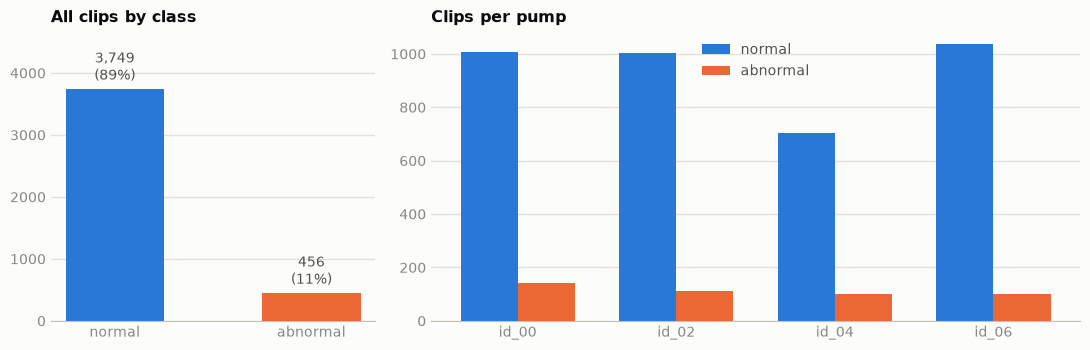

label,normal,abnormal,abnormal_share
pump_id,,,
id_00,1006,143,0.124
id_02,1005,111,0.099
id_04,702,100,0.125
id_06,1036,102,0.090


In [6]:
counts = manifest.groupby(["pump_id", "label"]).size().unstack()[["normal", "abnormal"]]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2]})
tot = manifest.label.value_counts()[["normal", "abnormal"]]
bars = axes[0].bar(tot.index, tot.values, color=[BLUE, ORANGE], width=0.5)
axes[0].bar_label(bars, labels=[f"{v:,}\n({v / tot.sum():.0%})" for v in tot.values], color=INK2, padding=3)
axes[0].set_title("All clips by class"); axes[0].set_ylim(0, tot.max() * 1.25)
x = np.arange(len(counts)); w = 0.36
axes[1].bar(x - w / 2, counts.normal, w, color=BLUE, label="normal")
axes[1].bar(x + w / 2, counts.abnormal, w, color=ORANGE, label="abnormal")
axes[1].set_xticks(x, counts.index); axes[1].set_title("Clips per pump"); axes[1].legend()
plt.tight_layout(); savefig("01_class_balance"); plt.show()
counts.assign(abnormal_share=lambda d: d.abnormal / (d.normal + d.abnormal))

The data is **imbalanced, about 8 normal clips for every abnormal one** (11 % abnormal). Accuracy alone would be
misleading: a model that always says "normal" is 89 % accurate and useless. I therefore report precision, recall, F1,
ROC-AUC and PR-AUC for the *abnormal* class, use class weights during training, and tune the decision threshold.

### 3.2 What a normal and an abnormal pump sound like

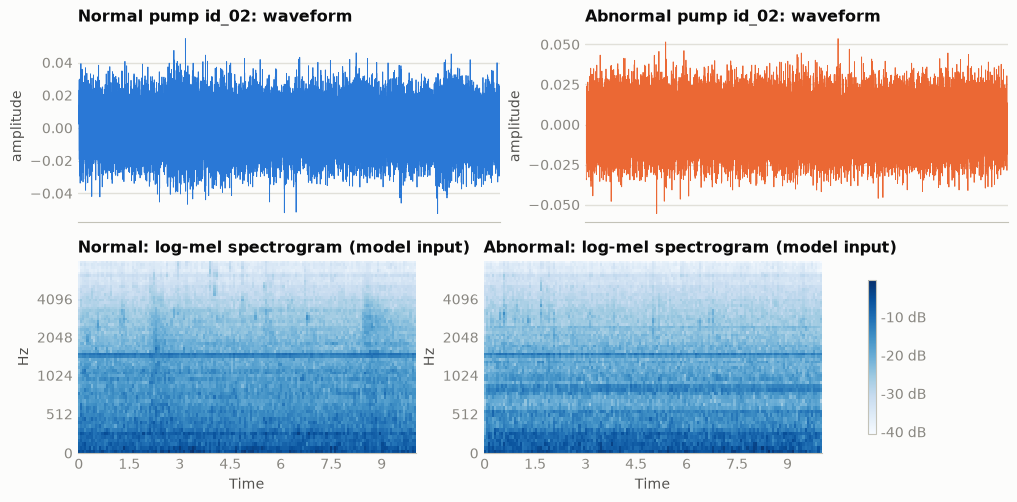

**normal**: `normal_id_02_a00000004.wav`

**abnormal**: `abnormal_id_02_b00000005.wav`

In [7]:
pump = "id_02"
ex = {lab: C.DATA_DIR / manifest.query("split == 'train' and label == @lab and pump_id == @pump").path.iloc[3]
      for lab in ("normal", "abnormal")}
fig, axes = plt.subplots(2, 2, figsize=(12, 5.5), sharex="col")
for col, (lab, path) in enumerate(ex.items()):
    y, sr = librosa.load(path, sr=C.SAMPLE_RATE)
    t = np.arange(len(y)) / sr
    axes[0, col].plot(t, y, color=CLASS_COLORS[lab], linewidth=0.6)
    axes[0, col].set_title(f"{lab.capitalize()} pump {pump}: waveform"); axes[0, col].set_ylabel("amplitude")
    img = librosa.display.specshow(P.log_mel_spectrogram(y), sr=sr, hop_length=C.HOP_LENGTH, x_axis="time",
                                   y_axis="mel", fmin=C.FMIN, fmax=C.FMAX, cmap="Blues", ax=axes[1, col])
    axes[1, col].set_title(f"{lab.capitalize()}: log-mel spectrogram (model input)"); axes[1, col].grid(False)
fig.colorbar(img, ax=axes[1, :], format="%+.0f dB", shrink=0.8)
savefig("02_waveform_spectrogram"); plt.show()
for lab, path in ex.items():
    display(Markdown(f"**{lab}**: `{path.name}`"), Audio(str(path)))

### 3.3 Interpretable acoustic features

To understand *what* differs between the classes, I compute summary features for every clip with
`P.handcrafted_features`: loudness (RMS energy and its fluctuation), brightness (spectral centroid), spread
(bandwidth, roll-off), noisiness (spectral flatness), zero-crossing rate, share of energy below 500 Hz and the
mean/std of 13 MFCCs. Features and log-mel spectrograms are extracted in parallel and cached.

In [8]:
CACHE = C.PROCESSED_DIR / "cache"
CACHE.mkdir(parents=True, exist_ok=True)

def load_split(split):
    paths, y = P.list_labelled_files(C.DATA_DIR / split)
    names = [p.name for p in paths]
    npz, csv_path = CACHE / f"{split}.npz", CACHE / f"{split}_features.csv"
    if npz.exists() and csv_path.exists():
        feats = pd.read_csv(csv_path)
        if feats.file.tolist() == names:
            with np.load(npz) as d:
                return d["X"], d["y"], feats
    t0 = time.time()
    X, feats = P.extract_dataset(paths, with_features=True)
    feats = pd.DataFrame(feats)
    feats.insert(0, "file", names)
    feats.insert(1, "label", [C.CLASSES[i] for i in y])
    feats.insert(2, "pump_id", ["id_" + n.split("_id_")[1][:2] for n in names])
    np.savez(npz, X=X, y=y)
    feats.to_csv(csv_path, index=False)
    print(f"{split}: extracted {len(paths)} clips in {time.time() - t0:.0f} s")
    return X, y, feats

X_all_train, y_all_train, F_train = load_split("train")
X_test, y_test, F_test = load_split("test")
X_new, y_new, F_new = load_split("new_batch")
print("log-mel tensors:", X_all_train.shape, X_test.shape, X_new.shape, "| dtype", X_all_train.dtype)
F_all = pd.concat([F_train.assign(split="train"), F_test.assign(split="test"), F_new.assign(split="new_batch")], ignore_index=True)
F_all.iloc[:, :12].head()

log-mel tensors: (3153, 64, 157, 1) (631, 64, 157, 1) (421, 64, 157, 1) | dtype float16


,file,label,pump_id,rms_mean,rms_std,spectral_centroid_hz,spectral_bandwidth_hz,spectral_rolloff_hz,spectral_flatness,zero_crossing_rate,low_band_energy_ratio,mfcc_1_mean
0,normal_id_00_a00000000.wav,normal,id_00,0.006,6.661e-04,1812.347,1977.513,4095.293,0.057,0.109,0.797,-195.315
1,normal_id_00_a00000001.wav,normal,id_00,0.006,5.924e-04,2886.423,2104.337,5441.680,0.314,0.299,0.192,-153.710
2,normal_id_00_a00000002.wav,normal,id_00,0.006,8.284e-04,2306.771,2220.141,5272.741,0.094,0.163,0.373,-183.573
3,normal_id_00_a00000003.wav,normal,id_00,0.006,8.136e-04,2295.384,2237.905,5351.015,0.088,0.164,0.328,-184.971
4,normal_id_00_a00000004.wav,normal,id_00,0.006,7.070e-04,2522.788,2369.603,5725.070,0.098,0.157,0.605,-190.538


In [9]:
SUMMARY = list(P.FEATURE_DESCRIPTIONS)
def separability(col):
    auc = roc_auc_score(F_all.label == "abnormal", F_all[col])
    return max(auc, 1 - auc), ("higher" if auc >= 0.5 else "lower")
rows = []
for col in SUMMARY:
    auc, direction = separability(col)
    med = F_all.groupby("label")[col].median()
    rows.append({"feature": col, "meaning": P.FEATURE_DESCRIPTIONS[col], "median_normal": med["normal"],
                 "median_abnormal": med["abnormal"], "abnormal_is": direction, "single_feature_auc": auc})
feature_table = pd.DataFrame(rows).sort_values("single_feature_auc", ascending=False).reset_index(drop=True)
feature_table

,feature,meaning,median_normal,median_abnormal,abnormal_is,single_feature_auc
0,rms_mean,Loudness (mean RMS energy),6.615e-03,6.943e-03,higher,0.710
1,rms_std,Loudness fluctuation (RMS std),6.972e-04,8.259e-04,higher,0.638
2,low_band_energy_ratio,Share of energy below 500 Hz,6.454e-01,5.623e-01,lower,0.601
3,spectral_flatness,Noisiness (spectral flatness),8.327e-02,1.005e-01,higher,0.589
4,zero_crossing_rate,Zero-crossing rate,1.482e-01,1.611e-01,higher,0.585
5,spectral_centroid_hz,"Brightness (spectral centroid, Hz)",2.201e+03,2.207e+03,higher,0.542
6,spectral_bandwidth_hz,"Spread of frequencies (bandwidth, Hz)",2.095e+03,2.089e+03,lower,0.525
7,spectral_rolloff_hz,85% energy roll-off (Hz),4.848e+03,4.793e+03,higher,0.505


### 3.4 Feature distributions: three stories

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


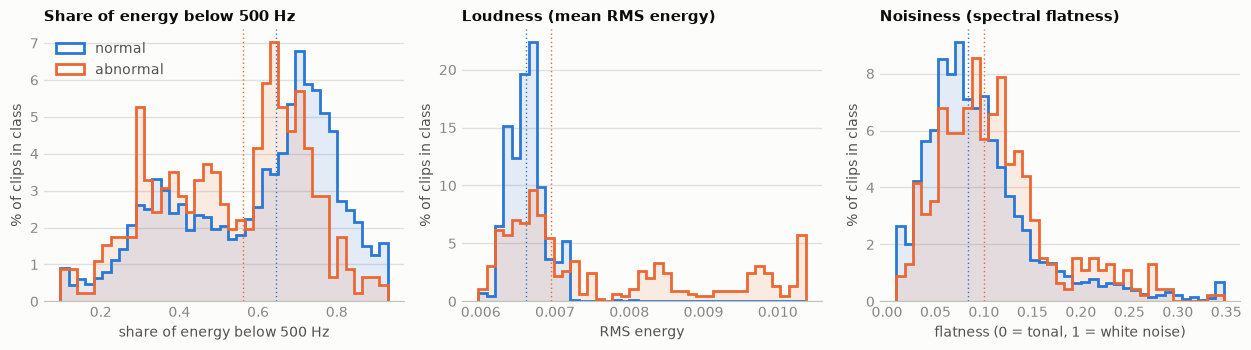

In [10]:
STORY_FEATURES = ['low_band_energy_ratio', 'rms_mean', 'spectral_flatness']  # picked after looking at the table above
UNITS = {"rms_mean": "RMS energy", "spectral_centroid_hz": "Hz", "spectral_flatness": "flatness (0 = tonal, 1 = white noise)",
         "low_band_energy_ratio": "share of energy below 500 Hz", "zero_crossing_rate": "crossings per sample",
         "spectral_bandwidth_hz": "Hz", "spectral_rolloff_hz": "Hz", "rms_std": "RMS std"}
fig, axes = plt.subplots(1, len(STORY_FEATURES), figsize=(4.2 * len(STORY_FEATURES), 3.6))
for ax, col in zip(axes, STORY_FEATURES):
    lo, hi = F_all[col].quantile([0.005, 0.995])
    bins = np.linspace(lo, hi, 40)
    for lab in ("normal", "abnormal"):
        vals = F_all.loc[F_all.label == lab, col].clip(lo, hi)
        w = np.ones(len(vals)) / len(vals) * 100
        ax.hist(vals, bins=bins, weights=w, color=CLASS_COLORS[lab], alpha=0.12, linewidth=0)
        ax.hist(vals, bins=bins, weights=w, histtype="step", color=CLASS_COLORS[lab], linewidth=2, label=lab)
        ax.axvline(vals.median(), color=CLASS_COLORS[lab], linewidth=1, linestyle=(0, (1, 2)))
    ax.set_title(P.FEATURE_DESCRIPTIONS[col], fontsize=10.5); ax.set_xlabel(UNITS.get(col, ""))
    ax.set_ylabel("% of clips in class")
axes[0].legend()
plt.tight_layout(); savefig("03_feature_distributions"); plt.show()

**Story 1: Where the energy sits (share of energy below 500 Hz).** A healthy pump is dominated by its low motor hum: for the median normal clip **65 %** of the energy is below 500 Hz. For abnormal clips this drops to **56 %**. The shift happens in *every one of the four pumps* (the abnormal median is 11-26 % lower per pump, §3.5), which makes this the most consistent signal in the data. Physically, leaks, clogging and contamination add turbulence and rattling: broadband energy *above* the hum, not a change in the hum itself.

**Story 2: Loudness (mean RMS energy).** Abnormal clips are slightly louder: median RMS 0.0069 vs 0.0066. On its own, loudness is the best summary feature (ROC-AUC 0.71), but it is not a reliable rule. Most of the effect comes from pump id_00, whose faulty clips are 28 % louder and whose loudness fluctuates 2.5x more within a clip, while pump id_04's faulty clips are *not* louder at all. A microphone placed a little closer would change this feature more than a fault does, which is another reason the model looks at the *shape* of the spectrum rather than its level alone.

**Story 3: Noisiness (spectral flatness).** Flatness measures how noise-like a sound is (0 = pure tone, 1 = white noise). Abnormal clips are noisier on average (median 0.100 vs 0.083), matching story 1: faults add broadband hiss. But the two distributions overlap heavily, because the pumps differ from each other more than normal differs from abnormal (next section).

### 3.5 Every pump has its own 'normal'

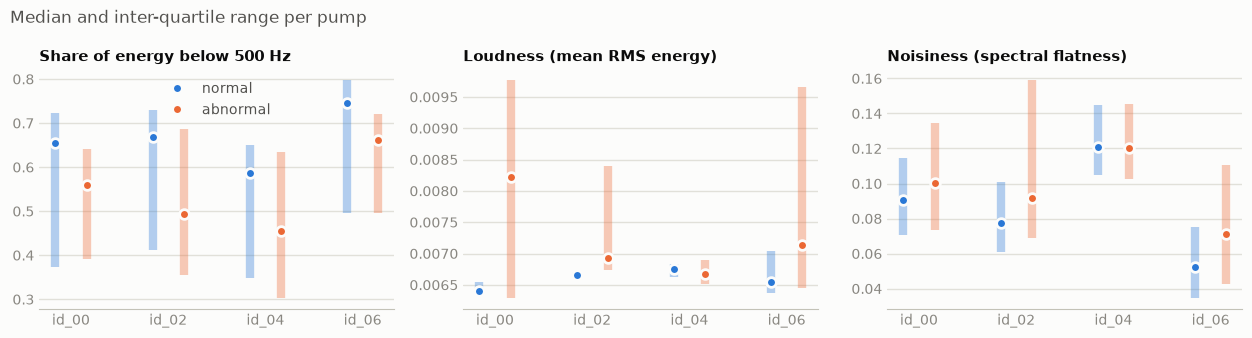

In [11]:
fig, axes = plt.subplots(1, len(STORY_FEATURES), figsize=(4.2 * len(STORY_FEATURES), 3.4), sharey=False)
pumps = sorted(F_all.pump_id.unique())
for ax, col in zip(axes, STORY_FEATURES):
    for i, pmp in enumerate(pumps):
        for j, lab in enumerate(("normal", "abnormal")):
            v = F_all.query("pump_id == @pmp and label == @lab")[col]
            q1, med, q3 = v.quantile([0.25, 0.5, 0.75])
            xpos = i + (j - 0.5) * 0.32
            ax.plot([xpos, xpos], [q1, q3], color=CLASS_COLORS[lab], linewidth=6, alpha=0.35, solid_capstyle="butt")
            ax.plot(xpos, med, "o", color=CLASS_COLORS[lab], markersize=7, markeredgecolor=SURFACE, markeredgewidth=2,
                    label=lab if i == 0 else None)
    ax.set_xticks(range(len(pumps)), pumps); ax.set_title(P.FEATURE_DESCRIPTIONS[col], fontsize=10.5)
axes[0].legend(); fig.suptitle("Median and inter-quartile range per pump", x=0.01, ha="left", color=INK2)
plt.tight_layout(); savefig("04_features_per_pump"); plt.show()

**Every pump has its own 'normal'.** Pump id_04's *healthy* sound is brighter and noisier (flatness 0.12, zero-crossing rate 0.19) than the *faulty* sound of pumps id_02 and id_06. Any single global threshold on loudness or noisiness therefore fails: it would flag healthy id_04 clips and miss faulty id_06 clips. Only the share of low-frequency energy moves in the same direction for every pump. **Implication for modelling:** the classifier has to learn combinations of frequency bands (what each pump normally sounds like and how a fault changes it) rather than one feature. This motivates a CNN on the full log-mel spectrogram rather than a model on a few summary numbers, and §5 tests that directly.

### 3.6 Average frequency profile

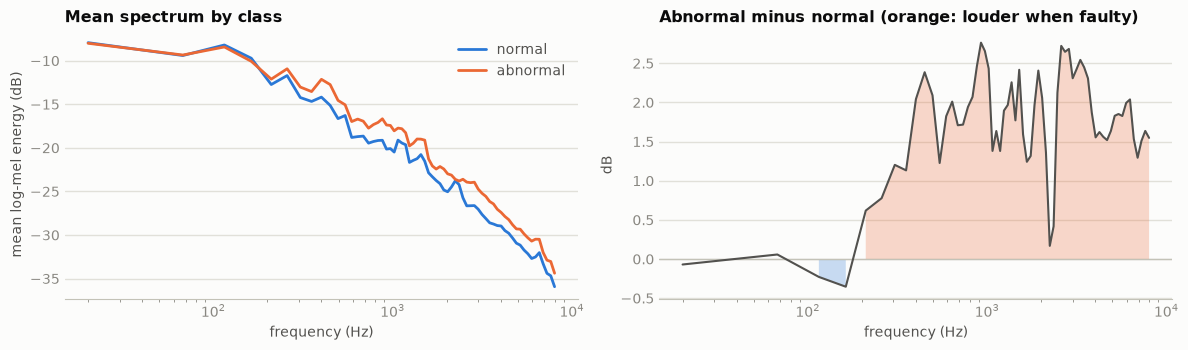

,band_hz,normal_db,abnormal_db,difference_db
0,924.0,-20.142,-17.379,2.763
1,2589.0,-26.652,-23.930,2.722
2,2856.0,-26.623,-23.940,2.683
3,971.0,-20.088,-17.432,2.656
4,2719.0,-26.640,-23.993,2.646


In [12]:
X_eda = np.concatenate([X_all_train, X_test, X_new])[..., 0].astype(np.float32)
y_eda = np.concatenate([y_all_train, y_test, y_new])
mel_hz = librosa.mel_frequencies(n_mels=C.N_MELS, fmin=C.FMIN, fmax=C.FMAX)
profile = {lab: X_eda[y_eda == i].mean(axis=(0, 2)) for i, lab in enumerate(C.CLASSES)}
diff = profile["abnormal"] - profile["normal"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for lab in C.CLASSES:
    axes[0].plot(mel_hz, profile[lab], color=CLASS_COLORS[lab], label=lab)
axes[0].set_xscale("log"); axes[0].set_xlabel("frequency (Hz)"); axes[0].set_ylabel("mean log-mel energy (dB)")
axes[0].set_title("Mean spectrum by class"); axes[0].legend()
axes[1].axhline(0, color=AXIS, linewidth=1)
axes[1].fill_between(mel_hz, 0, diff, where=diff > 0, color=ORANGE, alpha=0.25, linewidth=0)
axes[1].fill_between(mel_hz, 0, diff, where=diff <= 0, color=BLUE, alpha=0.25, linewidth=0)
axes[1].plot(mel_hz, diff, color=INK2, linewidth=1.5)
axes[1].set_xscale("log"); axes[1].set_xlabel("frequency (Hz)"); axes[1].set_ylabel("dB")
axes[1].set_title("Abnormal minus normal (orange: louder when faulty)")
plt.tight_layout(); savefig("05_mean_spectrum"); plt.show()
top = np.argsort(-np.abs(diff))[:5]
pd.DataFrame({"band_hz": mel_hz[top].round(0), "normal_db": profile["normal"][top], "abnormal_db": profile["abnormal"][top], "difference_db": diff[top]})

**Average frequency profile.** Below about 300 Hz the two classes are almost identical (within 0.4 dB): the motor hum does not change. From 300 Hz up to 8 kHz abnormal clips are consistently **about 2 dB louder**, with the largest gaps around 0.9-1.0 kHz and 2.5-3.3 kHz (+2.5 to +2.8 dB). This is the spectral version of stories 1 and 3: faults add energy in the mid and high bands. A 2 dB average shift is small compared with the spread between clips, so it is a useful signal for a model but not a rule a technician could apply by ear.

### 3.7 Dataset insights for the dashboard

The same numbers are exported to `data/processed/insights.json`, which the web app's **Insights** tab renders.

In [13]:
# short versions of the interpretations above, shown in the dashboard
INTERP_DASHBOARD = {
 "low_band_energy_ratio": "A healthy pump is dominated by its low hum: **65 %** of its energy is below 500 Hz. Faulty pumps drop to **56 %**, and the shift appears in **all four pumps**. Leaks and clogging add energy above the hum.",
 "rms_mean": "Faulty pumps are **slightly louder** (median RMS +5 %), the best single feature (ROC-AUC 0.71). But most of the effect comes from pump id_00 (+28 %); pump id_04's faulty clips are not louder at all.",
 "spectral_flatness": "Faulty pumps sound **noisier** (flatness 0.100 vs 0.083), but the classes overlap heavily: pump id_04's *healthy* sound is noisier than other pumps' faulty sound. No single threshold works."
}
INTERP_STORY = [
 "**Faults are rare:** 456 of 4,205 recordings (10.8 %) are abnormal, so accuracy alone is misleading. The model is judged on precision, recall, F1 and PR-AUC for the abnormal class.",
 "**A faulty pump keeps its hum but adds hiss:** below 300 Hz the classes are within 0.4 dB; from 300 Hz to 8 kHz abnormal clips are about **2 dB louder**, so the share of energy below 500 Hz falls from 65 % to 56 %.",
 "**Louder and noisier, but only a little:** abnormal clips are slightly louder and noisier, yet no single feature separates the classes well (best single-feature ROC-AUC **0.71**).",
 "**Every pump has its own normal:** pump id_04's healthy sound is noisier than other pumps' faulty sound, so fixed rules fail. The CNN learns patterns across 64 frequency bands and 10 s of time instead."
]
INTERP_SPECTRUM_SHORT = 'Below about 300 Hz the classes are almost identical: the motor hum does not change. From 300 Hz to 8 kHz abnormal pumps are **about 2 dB louder**, peaking around 0.9-1.0 kHz and 2.5-3.3 kHz. Faults add turbulence and rattle on top of the hum.'

def hist_payload(col, n_bins=30):
    lo, hi = F_all[col].quantile([0.005, 0.995])
    edges = np.linspace(lo, hi, n_bins + 1)
    centers = (edges[:-1] + edges[1:]) / 2
    out = {}
    for lab in C.CLASSES:
        v = F_all.loc[F_all.label == lab, col].clip(lo, hi)
        out[lab] = (np.histogram(v, bins=edges)[0] / len(v) * 100).round(2).tolist()
    return centers, out

def fmt(v):
    return f"{v:,.0f}" if abs(v) >= 100 else (f"{v:.3f}" if abs(v) >= 0.01 else f"{v:.4f}")

features_payload = []
for col in STORY_FEATURES:
    centers, h = hist_payload(col)
    auc, _ = separability(col)
    med = F_all.groupby("label")[col].median()
    features_payload.append({
        "key": col, "title": P.FEATURE_DESCRIPTIONS[col], "unit": UNITS.get(col, ""),
        "bin_labels": [fmt(c) for c in centers], "normal": h["normal"], "abnormal": h["abnormal"],
        "fmt_normal": fmt(med["normal"]), "fmt_abnormal": fmt(med["abnormal"]), "auc": round(auc, 3),
        "interpretation": INTERP_DASHBOARD[col],
    })

split_counts = {s: {**manifest.query("split == @s").label.value_counts().to_dict(), "total": int((manifest.split == s).sum())}
                for s in ("train", "test", "new_batch")}
insights = {
    "dataset": {
        "name": "DCASE 2020 Task 2 / MIMII - pump", "source_url": "https://zenodo.org/records/3678171",
        "n_clips": int(len(manifest)), "n_pumps": int(manifest.pump_id.nunique()),
        "clip_seconds": C.CLIP_SECONDS, "sample_rate": C.SAMPLE_RATE,
        "class_counts": manifest.label.value_counts().to_dict(), "split_counts": split_counts,
        "pump_counts": [{"pump": p, "normal": int(r.normal), "abnormal": int(r.abnormal)} for p, r in counts.iterrows()],
    },
    "story": INTERP_STORY,
    "spectrum": {"mel_hz": mel_hz.round(1).tolist(), "normal_db": profile["normal"].round(2).tolist(),
                 "abnormal_db": profile["abnormal"].round(2).tolist(), "interpretation": INTERP_SPECTRUM_SHORT},
    "features": features_payload,
    "ranking": [{"key": r.feature, "title": r.meaning, "auc": round(r.single_feature_auc, 3)} for r in feature_table.itertuples()],
}
C.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
C.INSIGHTS_PATH.write_text(json.dumps(insights, indent=1))
print("wrote", C.INSIGHTS_PATH.relative_to(ROOT), f"({C.INSIGHTS_PATH.stat().st_size / 1024:.0f} KB)")

wrote data/processed/insights.json (11 KB)


## 4. Preprocessing

The same functions run in this notebook, in the API (`/api/predict`) and in the retraining job, so training and
serving cannot drift apart.

| # | Step | Function | Why |
|---|---|---|---|
| 1 | Decode WAV/FLAC/OGG/MP3, mix to mono | `load_audio` | uploads may be stereo or another format |
| 2 | Resample to 16 kHz | `load_audio` | the model expects one fixed sample rate |
| 3 | Validate: not empty, at least 1 s, not silent, finite | `validate_audio` | bad uploads are rejected before they reach training |
| 4 | Cut into 10 s windows (short clips are looped, long ones split) | `split_into_clips` | fixed-size input; long recordings get several votes |
| 5 | Log-mel spectrogram: FFT 2048, hop 1024 (64 ms), 64 mel bands 20 Hz to 8 kHz, absolute dB | `log_mel_spectrogram` | compact time-frequency image; dB matches how loudness differences behave |
| 6 | Per-band standardisation, fitted on **training data only** | `Normalization` layer inside the model | the scaler is saved with the model, so serving cannot forget it |
| 7 | Augmentation, training only: random circular time shift, one frequency mask (up to 6 bands), one time mask (up to 20 frames) | `model._augment` | pump noise is stationary, so shifts are label-preserving; masks discourage relying on one narrow band |

In [14]:
path = ex["abnormal"]
y_raw, sr_raw = P.load_audio(path)
P.validate_audio(y_raw)
clips = P.split_into_clips(y_raw)
x = P.clips_to_model_input(clips)
print(f"1-2. decoded {path.name}: {y_raw.shape[0]:,} samples at {C.SAMPLE_RATE} Hz (file was {sr_raw} Hz) = {y_raw.size / C.SAMPLE_RATE:.1f} s")
print(f"3.   validation passed: peak amplitude {np.abs(y_raw).max():.3f}")
print(f"4.   {len(clips)} window(s) of {clips[0].size:,} samples")
print(f"5.   model input tensor {x.shape}  (clips, mel bands, frames, channel); range {x.min():.1f} to {x.max():.1f} dB")
long = np.concatenate([y_raw, y_raw[: int(4.5 * C.SAMPLE_RATE)]])
print(f"     a 14.5 s recording becomes {len(P.split_into_clips(long))} windows; a 3 s recording becomes {len(P.split_into_clips(y_raw[:3 * C.SAMPLE_RATE]))}")

1-2. decoded abnormal_id_02_b00000005.wav: 160,000 samples at 16000 Hz (file was 16000 Hz) = 10.0 s
3.   validation passed: peak amplitude 0.056
4.   1 window(s) of 160,000 samples
5.   model input tensor (1, 64, 157, 1)  (clips, mel bands, frames, channel); range -40.6 to -0.4 dB
     a 14.5 s recording becomes 1 windows; a 3 s recording becomes 1


**Train / validation split.** 15 % of the training folder, stratified by class, is held out for early stopping, model selection and threshold tuning.

In [15]:
idx_tr, idx_val = train_test_split(np.arange(len(y_all_train)), test_size=0.15, stratify=y_all_train, random_state=C.SEED)
X_tr, y_tr = X_all_train[idx_tr].astype(np.float32), y_all_train[idx_tr]
X_val, y_val = X_all_train[idx_val].astype(np.float32), y_all_train[idx_val]
F_tr, F_val = F_train.iloc[idx_tr], F_train.iloc[idx_val]
for name, yy in [("train", y_tr), ("validation", y_val), ("test", y_test)]:
    print(f"{name:<11} {len(yy):>5} clips | abnormal {yy.sum():>4} ({yy.mean():.1%})")
print("class weights:", {C.CLASSES[k]: round(v, 2) for k, v in M.class_weights(y_tr).items()})

train        2680 clips | abnormal  292 (10.9%)
validation    473 clips | abnormal   51 (10.8%)
test          631 clips | abnormal   68 (10.8%)
class weights: {'normal': 0.56, 'abnormal': 4.59}


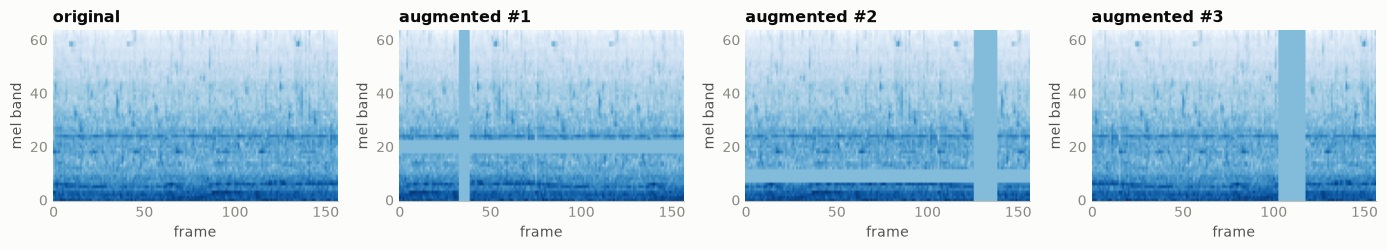

In [16]:
aug = M.make_dataset(X_tr[:1].repeat(3, 0), y_tr[:1].repeat(3, 0), batch_size=3, augment=True)
xb, _ = next(iter(aug))
fig, axes = plt.subplots(1, 4, figsize=(14, 2.6))
for ax, img, title in zip(axes, [X_tr[0]] + list(xb.numpy()), ["original"] + [f"augmented #{i}" for i in (1, 2, 3)]):
    ax.imshow(img[..., 0], origin="lower", aspect="auto", cmap="Blues"); ax.set_title(title); ax.grid(False)
    ax.set_xlabel("frame"); ax.set_ylabel("mel band")
plt.tight_layout(); savefig("06_augmentation"); plt.show()

## 5. Model creation and optimisation

I compare models on the **validation set** only; the test set stays untouched until §6.

* **Baselines on the handcrafted features (§3.3):** majority-class dummy, logistic regression (grid search over C,
  balanced class weights) and random forest (randomised search).
* **CNN on log-mel spectrograms (`src/model.py`):**
  * `CNN-vanilla`: same architecture without BatchNorm, Dropout, L2, augmentation, class weights or early stopping; plain Adam for a fixed 30 epochs.
  * `CNN-optimised`: BatchNorm + Dropout + L2 weight decay + SpecAugment-style augmentation + class weights + Adam + EarlyStopping (best weights restored) + ReduceLROnPlateau.
  * a small **hyperparameter search** over learning rate and dropout around the optimised configuration.

Model selection uses validation **PR-AUC** (average precision), which focuses on the rare abnormal class and does
not depend on a threshold.

In [17]:
experiments = []
def record(name, family, y_true, probs, notes="", threshold=0.5, **extra):
    m = M.metrics_from_probs(y_true, probs, threshold)
    experiments.append({"experiment": name, "family": family, **{k: m[k] for k in
        ("accuracy", "loss", "precision", "recall", "f1", "roc_auc", "pr_auc")}, **extra, "notes": notes})
    return m

feat_cols = [c for c in F_train.columns if c not in ("file", "label", "pump_id")]
cv = StratifiedKFold(5, shuffle=True, random_state=C.SEED)

dummy = DummyClassifier(strategy="most_frequent").fit(F_tr[feat_cols], y_tr)
record("Dummy (majority)", "baseline", y_val, dummy.predict_proba(F_val[feat_cols])[:, 1], "always predicts normal")

logreg = GridSearchCV(make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", max_iter=5000)),
                      {"logisticregression__C": [0.01, 0.1, 1, 10]}, scoring="average_precision", cv=cv, n_jobs=-1)
logreg.fit(F_tr[feat_cols], y_tr)
record("Logistic regression (grid search)", "classical", y_val, logreg.predict_proba(F_val[feat_cols])[:, 1],
       f"best {logreg.best_params_}")

rf = RandomizedSearchCV(RandomForestClassifier(class_weight="balanced_subsample", random_state=C.SEED, n_jobs=-1),
                        {"n_estimators": [200, 400], "max_depth": [None, 12, 20], "min_samples_leaf": [1, 2, 4],
                         "max_features": ["sqrt", 0.3]}, n_iter=10, scoring="average_precision", cv=cv,
                        random_state=C.SEED, n_jobs=-1)
rf.fit(F_tr[feat_cols], y_tr)
record("Random forest (randomised search)", "classical", y_val, rf.predict_proba(F_val[feat_cols])[:, 1],
       f"best {rf.best_params_}")
pd.DataFrame(experiments).drop(columns="notes")

,experiment,family,accuracy,loss,precision,recall,f1,roc_auc,pr_auc
0,Dummy (majority),baseline,0.892,1.738,0.000,0.000,0.000,0.500,0.108
1,Logistic regression (grid search),classical,0.835,0.419,0.366,0.725,0.487,0.878,0.642
2,Random forest (randomised search),classical,0.941,0.150,0.960,0.471,0.632,0.970,0.848


In [18]:
cnn_runs = {}
def run_cnn(name, notes, build_kw=None, train_kw=None):
    keras.utils.set_random_seed(C.SEED)
    model = M.build_cnn(X_tr, **(build_kw or {}))
    t0 = time.time()
    hist = M.train_model(model, X_tr, y_tr, X_val, y_val, **(train_kw or {}))
    secs = time.time() - t0
    probs = M.predict_proba(model, X_val)
    record(name, "cnn", y_val, probs, notes, epochs=len(hist.history["loss"]), train_seconds=round(secs),
           params=model.count_params())
    cnn_runs[name] = {"model": model, "history": M.history_to_dict(hist), "build_kw": build_kw or {}, "train_kw": train_kw or {}}
    print(f"{name}: {len(hist.history['loss'])} epochs in {secs:.0f} s | val PR-AUC {experiments[-1]['pr_auc']:.3f} | val F1 {experiments[-1]['f1']:.3f}")
    return model

vanilla = run_cnn("CNN-vanilla", "no BN/dropout/L2/augmentation/class weights/early stopping; Adam 1e-3, 30 epochs",
                  build_kw=dict(dropout=0, l2=0, batch_norm=False),
                  train_kw=dict(epochs=30, early_stopping=False, reduce_lr=False, use_class_weights=False, augment=False))
model_opt = run_cnn("CNN-optimised (lr 1e-3, dropout 0.3)", "BN + dropout 0.3 + L2 1e-4 + augmentation + class weights + early stopping + LR decay",
                    build_kw=dict(dropout=0.3, l2=1e-4), train_kw=dict(epochs=60, learning_rate=1e-3))
M.build_cnn(X_tr[:8]).summary()

E0000 00:00:1795094117.928115 11174718 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


CNN-vanilla: 30 epochs in 82 s | val PR-AUC 0.887 | val F1 0.833


E0000 00:00:1795094220.551269 11174718 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


CNN-optimised (lr 1e-3, dropout 0.3): 30 epochs in 102 s | val PR-AUC 0.945 | val F1 0.900


Model: "pump_sound_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ log_mel (InputLayer)            │ (None, 64, 157, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ band_norm (Normalization)       │ (None, 64, 157, 1)     │           129 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 157, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn1 (BatchNormalization)        │ (None, 64, 157, 16)    │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu1 (Activation)              │ (None, 64, 157, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 78, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 78, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn2 (BatchNormalization)        │ (None, 32, 78, 32)     │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu2 (Activation)              │ (None, 32, 78, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 39, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 39, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn3 (BatchNormalization)        │ (None, 16, 39, 64)     │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu3 (Activation)              │ (None, 16, 39, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 19, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv4 (Conv2D)                  │ (None, 8, 19, 128)     │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bn4 (BatchNormalization)        │ (None, 8, 19, 128)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ relu4 (Activation)              │ (None, 8, 19, 128)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_avg (AveragePooling2D)     │ (None, 8, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop1 (Dropout)                 │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop2 (Dropout)                 │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ p_abnormal (Dense)              │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 163,666 (639.32 KB)

 Trainable params: 163,057 (636.94 KB)

 Non-trainable params: 609 (2.38 KB)

**Hyperparameter search** around the optimised configuration (learning rate x dropout):

In [19]:
for lr, dr in [(1e-3, 0.5), (3e-4, 0.3), (3e-4, 0.5)]:
    run_cnn(f"CNN-optimised (lr {lr:g}, dropout {dr})", f"BN + dropout {dr} + L2 1e-4 + augmentation + class weights + early stopping + LR decay",
            build_kw=dict(dropout=dr, l2=1e-4), train_kw=dict(epochs=60, learning_rate=lr))
exp_df = pd.DataFrame(experiments)
exp_df.drop(columns="notes").style.format(precision=3, na_rep="").highlight_max(subset=["f1", "roc_auc", "pr_auc"], color="#cde2fb")

E0000 00:00:1795094314.676567 11174718 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


CNN-optimised (lr 0.001, dropout 0.5): 29 epochs in 94 s | val PR-AUC 0.887 | val F1 0.841


E0000 00:00:1795094418.323057 11174718 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


CNN-optimised (lr 0.0003, dropout 0.3): 30 epochs in 103 s | val PR-AUC 0.889 | val F1 0.822


E0000 00:00:1795094502.726606 11174718 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


CNN-optimised (lr 0.0003, dropout 0.5): 26 epochs in 84 s | val PR-AUC 0.788 | val F1 0.684


,experiment,family,accuracy,loss,precision,recall,f1,roc_auc,pr_auc,epochs,train_seconds,params
0,Dummy (majority),baseline,0.892,1.738,0.000,0.000,0.000,0.500,0.108,,,
1,Logistic regression (grid search),classical,0.835,0.419,0.366,0.725,0.487,0.878,0.642,,,
2,Random forest (randomised search),classical,0.941,0.150,0.960,0.471,0.632,0.970,0.848,,,
3,CNN-vanilla,cnn,0.966,0.184,0.889,0.784,0.833,0.964,0.887,30.000,82.000,162946.000
4,"CNN-optimised (lr 1e-3, dropout 0.3)",cnn,0.979,0.085,0.918,0.882,0.900,0.981,0.945,30.000,102.000,163666.000
5,"CNN-optimised (lr 0.001, dropout 0.5)",cnn,0.964,0.152,0.804,0.882,0.841,0.966,0.887,29.000,94.000,163666.000
6,"CNN-optimised (lr 0.0003, dropout 0.3)",cnn,0.960,0.144,0.786,0.863,0.822,0.964,0.889,30.000,103.000,163666.000
7,"CNN-optimised (lr 0.0003, dropout 0.5)",cnn,0.922,0.246,0.606,0.784,0.684,0.932,0.788,26.000,84.000,163666.000


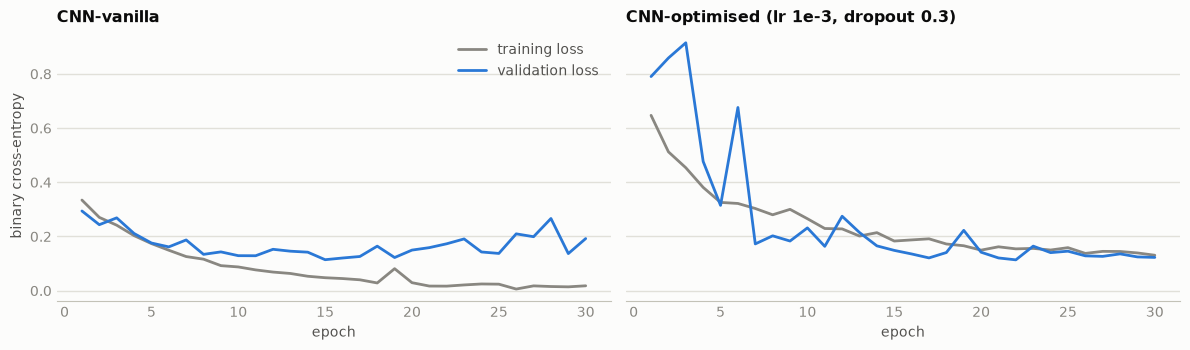

selected model: CNN-optimised (lr 1e-3, dropout 0.3)


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
best_name = exp_df.query("family == 'cnn' and experiment != 'CNN-vanilla'").sort_values("pr_auc", ascending=False).experiment.iloc[0]
for ax, name in zip(axes, ["CNN-vanilla", best_name]):
    h = cnn_runs[name]["history"]
    ep = np.arange(1, len(h["loss"]) + 1)
    ax.plot(ep, h["loss"], color=MUTED, label="training loss")
    ax.plot(ep, h["val_loss"], color=BLUE, label="validation loss")
    ax.set_title(name); ax.set_xlabel("epoch")
axes[0].set_ylabel("binary cross-entropy"); axes[0].legend()
plt.tight_layout(); savefig("07_learning_curves"); plt.show()
print("selected model:", best_name)

In [21]:
e = exp_df.set_index("experiment")
van, opt = e.loc["CNN-vanilla"], e.loc[best_name]
rf_, lr_ = e.loc["Random forest (randomised search)"], e.loc["Logistic regression (grid search)"]
hv = cnn_runs["CNN-vanilla"]["history"]; ho = cnn_runs[best_name]["history"]
v_best = int(np.argmin(hv["val_loss"])) + 1
v_rise = hv["val_loss"][-1] / min(hv["val_loss"])
vanilla_curve = (f"reaches its lowest validation loss at epoch {v_best} and then climbs to {v_rise:.1f}x that value by epoch 30 while "
                 f"training loss keeps falling to {hv['loss'][-1]:.3f}: it memorises the training clips (overfitting)"
                 if v_rise > 1.3 else f"is noisy and ends {v_rise:.1f}x above its best value")
display(Markdown(f"""
**What the experiments show (validation set).**

* **Accuracy alone is misleading:** the majority-class dummy scores {e.loc['Dummy (majority)', 'accuracy']:.3f} accuracy with F1 = 0.
* **Handcrafted summary features are not enough.** The tuned random forest reaches PR-AUC {rf_.pr_auc:.3f} / F1 {rf_.f1:.3f},
  logistic regression PR-AUC {lr_.pr_auc:.3f} / F1 {lr_.f1:.3f}. Averaging over the whole clip loses the band-by-band, pump-specific
  patterns found in §3.
* **The CNN on log-mel spectrograms is far stronger.** Even the vanilla CNN reaches PR-AUC {van.pr_auc:.3f}.
* **Optimisation matters.** The selected model, `{best_name}`, reaches PR-AUC **{opt.pr_auc:.3f}**, ROC-AUC **{opt.roc_auc:.3f}** and
  F1 **{opt.f1:.3f}**, against {van.pr_auc:.3f} / {van.roc_auc:.3f} / {van.f1:.3f} for the vanilla CNN. The vanilla model {vanilla_curve}.
  The optimised model's regularisation (BatchNorm, dropout, L2, augmentation) keeps validation loss close to training loss, and early
  stopping restored the weights from its best epoch ({int(np.argmin(ho['val_loss'])) + 1} of {len(ho['loss'])}).
* **Hyperparameters:** across the learning-rate x dropout grid, validation PR-AUC ranged from
  {e[e.index.str.startswith('CNN-optimised')].pr_auc.min():.3f} to {e[e.index.str.startswith('CNN-optimised')].pr_auc.max():.3f}; the best setting is used from here on.
"""))


**What the experiments show (validation set).**

* **Accuracy alone is misleading:** the majority-class dummy scores 0.892 accuracy with F1 = 0.
* **Handcrafted summary features are not enough.** The tuned random forest reaches PR-AUC 0.848 / F1 0.632,
  logistic regression PR-AUC 0.642 / F1 0.487. Averaging over the whole clip loses the band-by-band, pump-specific
  patterns found in §3.
* **The CNN on log-mel spectrograms is far stronger.** Even the vanilla CNN reaches PR-AUC 0.887.
* **Optimisation matters.** The selected model, `CNN-optimised (lr 1e-3, dropout 0.3)`, reaches PR-AUC **0.945**, ROC-AUC **0.981** and
  F1 **0.900**, against 0.887 / 0.964 / 0.833 for the vanilla CNN. The vanilla model reaches its lowest validation loss at epoch 15 and then climbs to 1.7x that value by epoch 30 while training loss keeps falling to 0.018: it memorises the training clips (overfitting).
  The optimised model's regularisation (BatchNorm, dropout, L2, augmentation) keeps validation loss close to training loss, and early
  stopping restored the weights from its best epoch (22 of 30).
* **Hyperparameters:** across the learning-rate x dropout grid, validation PR-AUC ranged from
  0.788 to 0.945; the best setting is used from here on.


## 6. Model testing on the held-out test set

The selected CNN's decision threshold is tuned on the **validation** set (maximum F1), then every model is
evaluated **once** on the test set. Metrics are for the *abnormal* (positive) class.

In [22]:
best = cnn_runs[best_name]["model"]
threshold = M.best_threshold(y_val, M.predict_proba(best, X_val))
print(f"decision threshold tuned on validation: {threshold:.2f}")

X_test32 = X_test.astype(np.float32)
p_best = M.predict_proba(best, X_test32)
p_van = M.predict_proba(vanilla, X_test32)
p_rf = rf.predict_proba(F_test[feat_cols])[:, 1]
p_lr = logreg.predict_proba(F_test[feat_cols])[:, 1]
test_metrics = M.metrics_from_probs(y_test, p_best, threshold)
rows = {f"{best_name} (threshold {threshold:.2f})": test_metrics,
        "CNN-vanilla (threshold 0.50)": M.metrics_from_probs(y_test, p_van, 0.5),
        "Random forest (threshold 0.50)": M.metrics_from_probs(y_test, p_rf, 0.5),
        "Logistic regression (threshold 0.50)": M.metrics_from_probs(y_test, p_lr, 0.5)}
test_table = pd.DataFrame(rows).T[["accuracy", "loss", "precision", "recall", "f1", "specificity", "balanced_accuracy", "roc_auc", "pr_auc"]].astype(float)
test_table

decision threshold tuned on validation: 0.52


,accuracy,loss,precision,recall,f1,specificity,balanced_accuracy,roc_auc,pr_auc
"CNN-optimised (lr 1e-3, dropout 0.3) (threshold 0.52)",0.976,0.075,0.884,0.897,0.891,0.986,0.941,0.989,0.959
CNN-vanilla (threshold 0.50),0.962,0.145,0.867,0.765,0.812,0.986,0.875,0.977,0.909
Random forest (threshold 0.50),0.948,0.139,0.973,0.529,0.686,0.998,0.764,0.965,0.864
Logistic regression (threshold 0.50),0.835,0.402,0.366,0.721,0.485,0.849,0.785,0.900,0.716


In [23]:
print(classification_report(y_test, (p_best >= threshold).astype(int), target_names=list(C.CLASSES), digits=3))

              precision    recall  f1-score   support

      normal      0.988     0.986     0.987       563
    abnormal      0.884     0.897     0.891        68

    accuracy                          0.976       631
   macro avg      0.936     0.941     0.939       631
weighted avg      0.976     0.976     0.976       631



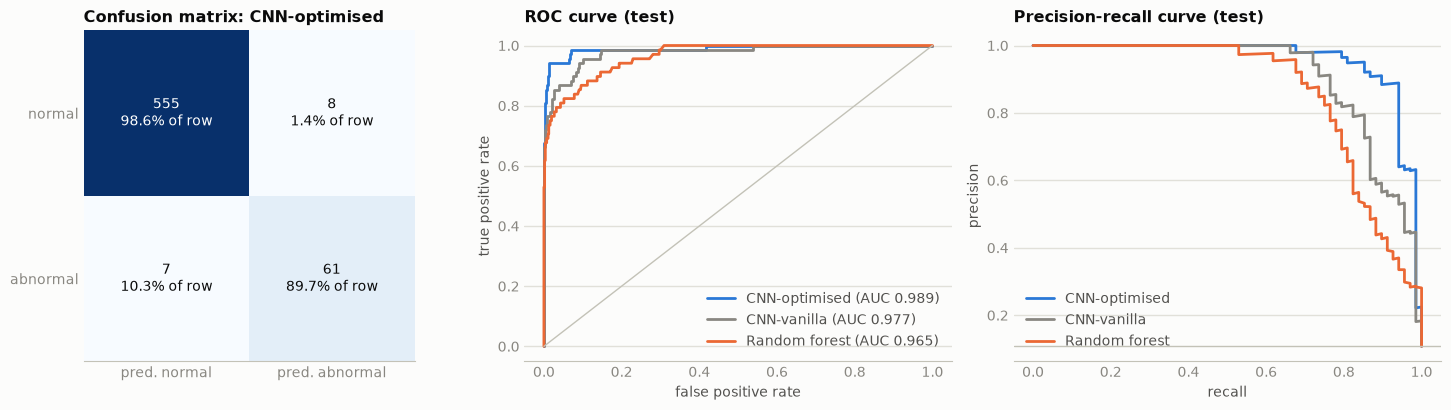

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cm = np.array(test_metrics["confusion_matrix"])
ax = axes[0]; ax.grid(False)
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v}\n{v / cm[i].sum():.1%} of row", ha="center", va="center", color="white" if v > cm.max() / 2 else INK)
ax.set_xticks([0, 1], ["pred. normal", "pred. abnormal"]); ax.set_yticks([0, 1], ["normal", "abnormal"])
ax.set_title(f"Confusion matrix: {best_name.split(' (')[0]}")
for name, p, col in [("CNN-optimised", p_best, BLUE), ("CNN-vanilla", p_van, MUTED), ("Random forest", p_rf, ORANGE)]:
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, color=col, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[2].plot(rec, prec, color=col, label=name)
axes[1].plot([0, 1], [0, 1], color=AXIS, linewidth=1); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC curve (test)"); axes[1].legend(loc="lower right")
axes[2].axhline(y_test.mean(), color=AXIS, linewidth=1); axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision")
axes[2].set_title("Precision-recall curve (test)"); axes[2].legend(loc="lower left")
plt.tight_layout(); savefig("08_test_evaluation"); plt.show()

In [25]:
F_eval = F_test.assign(p=p_best, pred=(p_best >= threshold).astype(int), y=y_test)
per_pump = F_eval.groupby("pump_id").apply(lambda d: pd.Series(M.metrics_from_probs(d.y.values, d.p.values, threshold))
                                          [["n", "accuracy", "precision", "recall", "f1", "roc_auc"]], include_groups=False)
per_pump

,n,accuracy,precision,recall,f1,roc_auc
pump_id,,,,,,
id_00,172,0.977,0.905,0.905,0.905,0.993
id_02,168,0.970,0.773,1.000,0.872,0.998
id_04,120,0.983,1.000,0.867,0.929,0.998
id_06,171,0.977,0.923,0.800,0.857,0.954


In [26]:
errors = F_eval.query("pred != y")[["file", "pump_id", "label", "p"]].sort_values("p")
print(f"{len(errors)} misclassified test clips out of {len(F_eval)}")
errors

15 misclassified test clips out of 631


,file,pump_id,label,p
628,abnormal_id_06_b00000085.wav,id_06,abnormal,0.013
563,abnormal_id_00_b00000001.wav,id_00,abnormal,0.164
604,abnormal_id_04_b00000015.wav,id_04,abnormal,0.176
573,abnormal_id_00_b00000092.wav,id_00,abnormal,0.183
601,abnormal_id_04_b00000000.wav,id_04,abnormal,0.484
617,abnormal_id_06_b00000022.wav,id_06,abnormal,0.487
618,abnormal_id_06_b00000023.wav,id_06,abnormal,0.513
526,normal_id_06_a00000778.wav,id_06,normal,0.535
201,normal_id_02_a00000323.wav,id_02,normal,0.537
190,normal_id_02_a00000258.wav,id_02,normal,0.605


In [27]:
tm = test_metrics
(tn, fp), (fn, tp) = tm["confusion_matrix"]
van_t, rf_t = test_table.iloc[1], test_table.iloc[2]
p_val = M.predict_proba(best, X_val)
val_t, val_05 = M.metrics_from_probs(y_val, p_val, threshold), M.metrics_from_probs(y_val, p_val, 0.5)
val_f1 = val_t["f1"]
weak = per_pump.f1.astype(float).idxmin()
weak_err = F_eval.query("pump_id == @weak and pred != y")
weak_fp, weak_fn = int((weak_err.y == 0).sum()), int((weak_err.y == 1).sum())
KEY = ["precision", "recall", "f1", "roc_auc", "pr_auc"]
NAMES = {"precision": "precision", "recall": "recall", "f1": "F1", "roc_auc": "ROC-AUC", "pr_auc": "PR-AUC"}
cnn_t = test_table.iloc[0]
def beats(other):
    return [NAMES[k] for k in KEY if cnn_t[k] > other[k]]
def loses(other):
    return [NAMES[k] for k in KEY if cnn_t[k] < other[k]]
def vs(name, other):
    b, l = beats(other), loses(other)
    s = f"the {name} on {', '.join(b) if len(b) < len(KEY) else 'every abnormal-class metric'}"
    if l:
        s += (f" (the {name} has higher {', '.join(l)}, but catches only {other['recall']:.0%} of faults)")
    return s
display(Markdown(f"""
**Test-set results ({tm['n']} clips never used for training, model selection or threshold tuning).**

* The CNN catches **{tp} of {tp + fn} faulty recordings** (recall {tm['recall']:.3f}) and raises **{fp} false alarms** among
  {tn + fp} healthy recordings (specificity {tm['specificity']:.3f}); precision {tm['precision']:.3f}, **F1 {tm['f1']:.3f}**,
  accuracy {tm['accuracy']:.3f}, log loss {tm['loss']:.3f}.
* Ranking quality is very high: **ROC-AUC {tm['roc_auc']:.3f}, PR-AUC {tm['pr_auc']:.3f}** (a random ranking would give PR-AUC
  {y_test.mean():.3f}, the share of abnormal clips).
* It beats {vs("vanilla CNN", van_t)}, and {vs("random forest", rf_t)}. F1: CNN {cnn_t.f1:.3f} vs vanilla {van_t.f1:.3f}
  vs random forest {rf_t.f1:.3f}.
* Test F1 ({tm['f1']:.3f}) is in line with validation F1 ({val_f1:.3f}), so selecting the model and threshold on the validation
  set did not overfit it.
* Per pump, the weakest is **{weak}** (F1 {per_pump.f1.astype(float).min():.3f}): {weak_fp} false alarm(s) and {weak_fn} missed fault(s).
  Most of the {len(errors)} errors sit close to the threshold (see the table above), i.e. the model is uncertain rather than confidently wrong.
* The decision threshold tuned on validation is **{threshold:.2f}**. On the validation set, moving it from 0.50 to {threshold:.2f}
  changed precision {val_05['precision']:.3f} -> {val_t['precision']:.3f}, recall {val_05['recall']:.3f} -> {val_t['recall']:.3f}
  and F1 {val_05['f1']:.3f} -> {val_t['f1']:.3f}. A maintenance team that would rather inspect more pumps than miss a fault can
  lower it and move along the precision-recall curve above; it is stored in the registry with the model, so changing it needs no retraining.
"""))


**Test-set results (631 clips never used for training, model selection or threshold tuning).**

* The CNN catches **61 of 68 faulty recordings** (recall 0.897) and raises **8 false alarms** among
  563 healthy recordings (specificity 0.986); precision 0.884, **F1 0.891**,
  accuracy 0.976, log loss 0.075.
* Ranking quality is very high: **ROC-AUC 0.989, PR-AUC 0.959** (a random ranking would give PR-AUC
  0.108, the share of abnormal clips).
* It beats the vanilla CNN on every abnormal-class metric, and the random forest on recall, F1, ROC-AUC, PR-AUC (the random forest has higher precision, but catches only 53% of faults). F1: CNN 0.891 vs vanilla 0.812
  vs random forest 0.686.
* Test F1 (0.891) is in line with validation F1 (0.909), so selecting the model and threshold on the validation
  set did not overfit it.
* Per pump, the weakest is **id_06** (F1 0.857): 1 false alarm(s) and 3 missed fault(s).
  Most of the 15 errors sit close to the threshold (see the table above), i.e. the model is uncertain rather than confidently wrong.
* The decision threshold tuned on validation is **0.52**. On the validation set, moving it from 0.50 to 0.52
  changed precision 0.918 -> 0.938, recall 0.882 -> 0.882
  and F1 0.900 -> 0.909. A maintenance team that would rather inspect more pumps than miss a fault can
  lower it and move along the precision-recall curve above; it is stored in the registry with the model, so changing it needs no retraining.


## 7. Saving the model and the artefacts used in production

* `models/pump_sound_cnn.keras` (Keras native format, served by the API) and `models/pump_sound_cnn.h5` (HDF5 copy)
* `models/registry.json`: version `v1` with its threshold, test metrics, training history and preprocessing settings
* `data/processed/test_features.npz`: the held-out test set as log-mel tensors, for **evaluation in production** and for comparing models after every retrain
* `data/processed/replay_features.npz`: a replay buffer of original training data mixed into every retrain, so the model does not forget what it knew
* `data/samples/*.wav`: correctly classified test clips for the demo
* `reports/experiments.csv`: every experiment above

In [28]:
# reset the registry, the model trained here is v1
for f in (C.MODELS_DIR / "versions").glob("*.keras"):
    f.unlink()
registry.save_registry({"current": None, "versions": {}})
M.save_model(best, C.MODELS_DIR / f"{C.MODEL_NAME}.keras", also_h5=True)
registry.register(filename=f"{C.MODEL_NAME}.keras", test_metrics=test_metrics, threshold=threshold, trigger="initial",
                  history=cnn_runs[best_name]["history"], train_samples=int(len(y_tr)),
                  prevalence=float(y_tr.mean()), version="v1",
                  notes=f"{best_name}; selected on validation PR-AUC")

np.savez_compressed(C.TEST_FEATURES_PATH, X=X_test.astype(np.float16), y=y_test)
rng = np.random.default_rng(C.SEED)
ab, no = np.where(y_all_train == 1)[0], np.where(y_all_train == 0)[0]
replay_idx = np.sort(np.concatenate([ab, rng.choice(no, size=1200 - len(ab), replace=False)]))
np.savez_compressed(C.REPLAY_FEATURES_PATH, X=X_all_train[replay_idx].astype(np.float16), y=y_all_train[replay_idx])

C.SAMPLES_DIR.mkdir(parents=True, exist_ok=True)
for f in C.SAMPLES_DIR.glob("*.wav"):
    f.unlink()
confident = F_eval.assign(conf=np.where(F_eval.pred == 1, F_eval.p, 1 - F_eval.p)).query("pred == y and conf >= 0.9")
picks = confident.groupby(["pump_id", "label"]).head(1).sort_values(["label", "pump_id"], ascending=[False, True])
for f, lab in zip(picks.file, picks.label):
    shutil.copy2(C.TEST_DIR / lab / f, C.SAMPLES_DIR / f)

(ROOT / "reports").mkdir(exist_ok=True)
exp_df.to_csv(ROOT / "reports" / "experiments.csv", index=False)
test_table.to_csv(ROOT / "reports" / "test_metrics.csv")
for p in [C.MODELS_DIR / f"{C.MODEL_NAME}.keras", C.MODELS_DIR / f"{C.MODEL_NAME}.h5", C.REGISTRY_PATH,
          C.TEST_FEATURES_PATH, C.REPLAY_FEATURES_PATH, C.INSIGHTS_PATH]:
    print(f"{str(p.relative_to(ROOT)):<40} {p.stat().st_size / 1e6:6.2f} MB")
print("demo samples:", sorted(f.name for f in C.SAMPLES_DIR.glob('*.wav')))

models/pump_sound_cnn.keras                2.06 MB
models/pump_sound_cnn.h5                   2.06 MB
models/registry.json                       0.01 MB
data/processed/test_features.npz           9.75 MB
data/processed/replay_features.npz        18.57 MB
data/processed/insights.json               0.01 MB
demo samples: ['abnormal_id_00_b00000014.wav', 'abnormal_id_02_b00000003.wav', 'abnormal_id_04_b00000006.wav', 'abnormal_id_06_b00000017.wav', 'normal_id_00_a00000011.wav', 'normal_id_02_a00000010.wav', 'normal_id_04_a00000007.wav', 'normal_id_06_a00000007.wav']


In [29]:
# check both saved files load and give the same predictions
for ext in ("keras", "h5"):
    reloaded = M.load_model(C.MODELS_DIR / f"{C.MODEL_NAME}.{ext}")
    diff = np.abs(M.predict_proba(reloaded, X_test32[:64]) - p_best[:64]).max()
    print(f".{ext}: max |difference| = {diff:.2e}")

.keras: max |difference| = 0.00e+00


.h5: max |difference| = 0.00e+00


## 8. Prediction functions

`src/prediction.py` is what the API calls. It reads the current version from the registry, preprocesses a file
exactly as above, averages the window probabilities and applies the tuned threshold.

In [30]:
from src.prediction import predict_file, get_predictor

rows = []
for f in sorted(C.SAMPLES_DIR.glob("*.wav")):
    r = predict_file(f)
    rows.append({"file": f.name, "true label": P.infer_label(f.name), "predicted": r["label"],
                 "P(abnormal)": r["probability_abnormal"], "confidence": r["confidence"],
                 "correct": P.infer_label(f.name) == r["label"], "ms": r["preprocess_ms"] + r["inference_ms"]})
pd.DataFrame(rows)

,file,true label,predicted,P(abnormal),confidence,correct,ms
0,abnormal_id_00_b00000014.wav,abnormal,abnormal,1.000e+00,1.000,True,18.77
1,abnormal_id_02_b00000003.wav,abnormal,abnormal,9.734e-01,0.973,True,9.76
2,abnormal_id_04_b00000006.wav,abnormal,abnormal,1.000e+00,1.000,True,9.21
3,abnormal_id_06_b00000017.wav,abnormal,abnormal,9.357e-01,0.936,True,10.38
4,normal_id_00_a00000011.wav,normal,normal,5.900e-03,0.994,True,9.43
5,normal_id_02_a00000010.wav,normal,normal,1.000e-04,1.000,True,11.93
6,normal_id_04_a00000007.wav,normal,normal,2.510e-02,0.975,True,10.27
7,normal_id_06_a00000007.wav,normal,normal,1.740e-02,0.983,True,10.50


In [31]:
# recordings that are not 10 s: 25 s gets split into 3 windows, 4 s gets looped to 10 s
import io
rows = []
for f in sorted(C.SAMPLES_DIR.glob("*_id_02_*.wav")):
    y0, _ = sf.read(f)
    for secs in (25, 4):
        n_samples = int(secs * C.SAMPLE_RATE)
        y_var = np.tile(y0, int(np.ceil(n_samples / len(y0))))[:n_samples]
        buf = io.BytesIO(); sf.write(buf, y_var, C.SAMPLE_RATE, format="WAV")
        r = get_predictor().predict(buf.getvalue(), filename=f.name)
        rows.append({"source clip": f.name, "length (s)": secs, "windows": r["n_clips"],
                     "window P(abnormal)": r["window_probabilities"], "mean": r["probability_abnormal"], "predicted": r["label"]})
pd.DataFrame(rows)

,source clip,length (s),windows,window P(abnormal),mean,predicted
0,abnormal_id_02_b00000003.wav,25,3,"[0.973, 0.973, 0.953]",9.667e-01,abnormal
1,abnormal_id_02_b00000003.wav,4,1,[0.95],9.504e-01,abnormal
2,normal_id_02_a00000010.wav,25,3,"[0.0, 0.0, 0.0]",1.000e-04,normal
3,normal_id_02_a00000010.wav,4,1,[0.0],1.000e-04,normal


## 9. Retraining: the saved model as the pre-trained starting point

In production (`src/retrain.py`, triggered from the dashboard, `POST /api/retrain`, or automatically) retraining:

1. stores uploaded recordings in the **SQLite database** (raw audio bytes + label),
2. **preprocesses** them with the same functions (validation, 10 s windows, log-mel), storing features back in the DB,
3. **loads the current production model** and fine-tunes it with a 5x smaller learning rate on new uploads + the
   replay buffer (early stopping, class weights, augmentation); the candidate's threshold is re-tuned on its validation
   split with samples **re-weighted to the real 11 % share of faults**, because the replay buffer keeps every abnormal
   training clip (28 % abnormal) and an unweighted F1 would pick a threshold that raises too many false alarms,
4. evaluates the old and new model on the same held-out test set,
5. promotes the new version only if its test PR-AUC does not drop by more than 0.005 and its F1 by more than 0.03;
   otherwise it keeps the current one (champion/challenger on a fixed hold-out set).

**Triggers:** a manual button, plus an automatic trigger after each upload when (a) the number of new labelled
samples reaches a threshold (default 100), or (b) the current model's F1 on the newly uploaded batch drops below a
floor (default 0.80), a sign of data drift.

Below, the same `M.fine_tune` call runs on the held-out `new_batch` folder to show the effect (nothing is registered here).

In [32]:
with np.load(C.REPLAY_FEATURES_PATH) as d:
    X_rep, y_rep = d["X"], d["y"]
X_ft = np.concatenate([X_rep, X_new]).astype(np.float32)
y_ft = np.concatenate([y_rep, y_new])
Xa, Xb, ya, yb = train_test_split(X_ft, y_ft, test_size=0.15, stratify=y_ft, random_state=C.SEED)

pretrained = M.load_model(C.MODELS_DIR / f"{C.MODEL_NAME}.keras")  # start from the saved model
before = M.evaluate_model(pretrained, X_test32, y_test, threshold)
t0 = time.time()
hist_ft = M.fine_tune(pretrained, Xa, ya, Xb, yb)
th_ft = M.best_threshold(yb, M.predict_proba(pretrained, Xb), prevalence=float(y_tr.mean()))
after = M.evaluate_model(pretrained, X_test32, y_test, th_ft)
print(f"fine-tuned on {len(Xa)} samples ({len(X_new)} new) for {len(hist_ft.history['loss'])} epochs in {time.time() - t0:.0f} s")
pd.DataFrame({"before (v1)": before, "after fine-tuning": after}).loc[["accuracy", "loss", "precision", "recall", "f1", "roc_auc", "pr_auc"]].astype(float)

E0000 00:00:1795094518.713071 11174718 node_def_util.cc:682] NodeDef mentions attribute use_unbounded_threadpool which is not in the op definition: Op<name=MapDataset; signature=input_dataset:variant, other_arguments: -> handle:variant; attr=f:func; attr=Targuments:list(type),min=0; attr=output_types:list(type),min=1; attr=output_shapes:list(shape),min=1; attr=use_inter_op_parallelism:bool,default=true; attr=preserve_cardinality:bool,default=false; attr=force_synchronous:bool,default=false; attr=metadata:string,default=""> This may be expected if your graph generating binary is newer  than this binary. Unknown attributes will be ignored. NodeDef: {{node ParallelMapDatasetV2/_14}}


fine-tuned on 1377 samples (421 new) for 6 epochs in 12 s


,before (v1),after fine-tuning
accuracy,0.976,0.983
loss,0.075,0.087
precision,0.884,0.983
recall,0.897,0.853
f1,0.891,0.913
roc_auc,0.989,0.992
pr_auc,0.959,0.965


In [33]:
from src.retrain import promotion_decision
promote, why = promotion_decision(before, after)
display(Markdown(f"""
Fine-tuning the saved model on **{len(X_new)} new recordings** plus the replay buffer took {len(hist_ft.history['loss'])} epochs.
On the same held-out test set, F1 went from **{before['f1']:.3f} to {after['f1']:.3f}**, ROC-AUC from {before['roc_auc']:.3f} to
{after['roc_auc']:.3f}, PR-AUC from {before['pr_auc']:.3f} to {after['pr_auc']:.3f} and recall from {before['recall']:.3f} to {after['recall']:.3f}.
Under the production promotion rule (test PR-AUC may not drop by more than {C.PROMOTION_PR_AUC_TOLERANCE}, F1 by more than
{C.PROMOTION_F1_TOLERANCE}) this candidate **would {'be promoted' if promote else 'be rejected, and the current model kept'}**.
The gate matters: a retrain on a small or noisy upload can make the model worse, and the registry only serves a new version when
the held-out evidence supports it. PR-AUC is the primary criterion because it does not depend on the re-tuned threshold, and it
is the same metric used to select the model in §5.
"""))


Fine-tuning the saved model on **421 new recordings** plus the replay buffer took 6 epochs.
On the same held-out test set, F1 went from **0.891 to 0.913**, ROC-AUC from 0.989 to
0.992, PR-AUC from 0.959 to 0.965 and recall from 0.897 to 0.853.
Under the production promotion rule (test PR-AUC may not drop by more than 0.005, F1 by more than
0.03) this candidate **would be promoted**.
The gate matters: a retrain on a small or noisy upload can make the model worse, and the registry only serves a new version when
the held-out evidence supports it. PR-AUC is the primary criterion because it does not depend on the re-tuned threshold, and it
is the same metric used to select the model in §5.


In [34]:
display(Markdown(f"""
## 10. Conclusions

* **Sound carries the signal records could not.** Faulty pumps keep their low hum but add about 2 dB of energy from 300 Hz to 8 kHz,
  which shifts the low-band energy share from 65 % to 56 % in every pump (§3).
* **A spectrogram CNN is needed.** Single features top out at ROC-AUC 0.71 and pumps differ from each other more than normal from
  abnormal; the optimised CNN reaches **test ROC-AUC {test_metrics['roc_auc']:.3f}, F1 {test_metrics['f1']:.3f}, recall
  {test_metrics['recall']:.3f}** for the abnormal class.
* **Optimisation pays off:** regularisation, augmentation, class weights, early stopping, LR decay and a tuned threshold raise test F1
  from {test_table.iloc[1].f1:.3f} (vanilla CNN) to {test_metrics['f1']:.3f} and PR-AUC from {test_table.iloc[1].pr_auc:.3f} to {test_metrics['pr_auc']:.3f}.
* **Ready for production:** the model, its threshold and test metrics are versioned in `models/registry.json`; the API serves it and
  retraining fine-tunes the saved model on uploaded data, then promotes it only if the held-out test set agrees.

**Limitations and next steps.** All four pumps come from one factory dataset with mixed-in factory noise; recordings from Tanzanian
hand pumps and boreholes would differ (different machines, wind, people). The upload-and-retrain loop is designed for exactly that:
technicians label a batch of local recordings, upload them, and the model adapts. Other next steps: pump-specific thresholds and
an anomaly-detection model trained only on normal sounds for pumps with no recorded faults.
"""))


## 10. Conclusions

* **Sound carries the signal records could not.** Faulty pumps keep their low hum but add about 2 dB of energy from 300 Hz to 8 kHz,
  which shifts the low-band energy share from 65 % to 56 % in every pump (§3).
* **A spectrogram CNN is needed.** Single features top out at ROC-AUC 0.71 and pumps differ from each other more than normal from
  abnormal; the optimised CNN reaches **test ROC-AUC 0.989, F1 0.891, recall
  0.897** for the abnormal class.
* **Optimisation pays off:** regularisation, augmentation, class weights, early stopping, LR decay and a tuned threshold raise test F1
  from 0.812 (vanilla CNN) to 0.891 and PR-AUC from 0.909 to 0.959.
* **Ready for production:** the model, its threshold and test metrics are versioned in `models/registry.json`; the API serves it and
  retraining fine-tunes the saved model on uploaded data, then promotes it only if the held-out test set agrees.

**Limitations and next steps.** All four pumps come from one factory dataset with mixed-in factory noise; recordings from Tanzanian
hand pumps and boreholes would differ (different machines, wind, people). The upload-and-retrain loop is designed for exactly that:
technicians label a batch of local recordings, upload them, and the model adapts. Other next steps: pump-specific thresholds and
an anomaly-detection model trained only on normal sounds for pumps with no recorded faults.
